# 03 — Deep Learning Forecasting (LSTM)

Picks up from notebooks 01 and 02. We build two LSTM variants and compare them with the baselines and the Random Forest **on exactly the same test hours**:

1. **Univariate LSTM** — sees only the last 24 hours of usage.
2. **Multivariate LSTM** — also sees hour, day-of-week and the 24-hour rolling mean.

What is different from a quick first attempt (and why):
- The scaler is fitted on the **training period only** (fitting it on all data leaks test information).
- The validation set is a **separate validation period**, not the test set. Early stopping watches it.
- Sequences are only built from windows with **no missing hours**, and the target must be a **real measured hour**.
- All models are compared on the **common test hours** (the LSTM needs 24 clean hours, the Random Forest needs 168, so their test rows differ slightly).

## 3.1 Load data from the previous notebooks

In [ ]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

IN_DIR1 = "/kaggle/input/notebooks/azizullahasad/01-data-cleaning-and-eda" 
IN_DIR = "/kaggle/input/notebooks/azizullahasad/02-feature-enginering-and-baseline-model"
WORK_DIR = "/kaggle/working/"  
np.random.seed(42)
tf.random.set_seed(42)

hourly = pd.read_csv(f"{IN_DIR1}/house38_hourly_clean.csv", index_col=0, parse_dates=True)
train = pd.read_csv(f"{IN_DIR}/house38_train.csv", index_col=0, parse_dates=True)
val = pd.read_csv(f"{IN_DIR}/house38_val.csv", index_col=0, parse_dates=True)
test = pd.read_csv(f"{IN_DIR}/house38_test.csv", index_col=0, parse_dates=True)

train_end = train.index.max()      # same time cut-offs as notebook 02
val_end = val.index.max()
print("train ends:", train_end, "| val ends:", val_end)


def smape(actual, predicted):
    actual, predicted = np.asarray(actual), np.asarray(predicted)
    return 100 * np.mean(2 * np.abs(actual - predicted) / (np.abs(actual) + np.abs(predicted) + 1e-8))

train ends: 2024-05-06 08:00:00 | val ends: 2024-06-09 15:00:00


## 3.2 Scale the data and build 24-hour sequences

Neural networks train better on scaled inputs. Each training example is: *the last 24 hours* → *the next hour*.

In [3]:
SEQ_LEN = 24

data = pd.DataFrame(index=hourly.index)
data["usage"] = hourly["Usage (kW)"]
data["hour"] = hourly.index.hour
data["dow"] = hourly.index.dayofweek
data["roll_mean_24"] = data["usage"].rolling(24, min_periods=12).mean()   # past hours only (window ends at t-1 for the target t)
observed = hourly["observed"].values

# scaler learns min/max from the TRAINING period only
scaler = MinMaxScaler()
scaler.fit(data[data.index <= train_end])
scaled = scaler.transform(data)                       # shape (hours, 4); missing hours stay NaN
usage_min, usage_range = scaler.data_min_[0], scaler.data_range_[0]


def make_sequences(values, index, observed, seq_len=SEQ_LEN):
    X, y, times = [], [], []
    for i in range(seq_len, len(values)):
        window = values[i - seq_len: i]
        target = values[i, 0]
        if np.isnan(window).any() or np.isnan(target) or not observed[i]:
            continue                                   # skip windows with missing data / filled targets
        X.append(window)
        y.append(target)
        times.append(index[i])
    return np.array(X), np.array(y), pd.DatetimeIndex(times)


X_multi, y_all, times = make_sequences(scaled, data.index, observed)
X_uni = X_multi[:, :, :1]                              # univariate = usage column only

train_m = times <= train_end
val_m = (times > train_end) & (times <= val_end)
test_m = times > val_end
print("sequences  train / val / test:", train_m.sum(), val_m.sum(), test_m.sum())

sequences  train / val / test: 5889 823 1645


## 3.3 Train both LSTMs

Early stopping stops training when the **validation** loss stops improving and restores the best weights.

In [4]:
def build_lstm(n_features):
    model = Sequential([
        Input(shape=(SEQ_LEN, n_features)),
        LSTM(50, return_sequences=True),
        LSTM(50),
        Dense(25, activation="relu"),
        Dense(1),
    ])
    model.compile(optimizer="adam", loss="mse")
    return model


def fit_lstm(X, y):
    model = build_lstm(X.shape[2])
    early = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    model.fit(X[train_m], y[train_m], validation_data=(X[val_m], y[val_m]),
              epochs=30, batch_size=32, callbacks=[early], verbose=2)
    return model


print("--- Univariate LSTM ---")
lstm_uni = fit_lstm(X_uni, y_all)
print("\n--- Multivariate LSTM ---")
lstm_multi = fit_lstm(X_multi, y_all)

--- Univariate LSTM ---


I0000 00:00:1792570099.094101      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792570099.097432      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/30
185/185 - 5s - 26ms/step - loss: 0.0153 - val_loss: 0.0816
Epoch 2/30
185/185 - 1s - 8ms/step - loss: 0.0130 - val_loss: 0.0761
Epoch 3/30
185/185 - 1s - 7ms/step - loss: 0.0114 - val_loss: 0.0863
Epoch 4/30
185/185 - 1s - 7ms/step - loss: 0.0104 - val_loss: 0.0807
Epoch 5/30
185/185 - 1s - 7ms/step - loss: 0.0103 - val_loss: 0.0717
Epoch 6/30
185/185 - 1s - 7ms/step - loss: 0.0102 - val_loss: 0.0678
Epoch 7/30
185/185 - 1s - 7ms/step - loss: 0.0101 - val_loss: 0.0664
Epoch 8/30
185/185 - 1s - 8ms/step - loss: 0.0101 - val_loss: 0.0641
Epoch 9/30
185/185 - 1s - 7ms/step - loss: 0.0100 - val_loss: 0.0653
Epoch 10/30
185/185 - 1s - 7ms/step - loss: 0.0098 - val_loss: 0.0618
Epoch 11/30
185/185 - 1s - 7ms/step - loss: 0.0096 - val_loss: 0.0638
Epoch 12/30
185/185 - 1s - 7ms/step - loss: 0.0095 - val_loss: 0.0588
Epoch 13/30
185/185 - 1s - 7ms/step - loss: 0.0093 - val_loss: 0.0633
Epoch 14/30
185/185 - 1s - 7ms/step - loss: 0.0092 - val_loss: 0.0623
Epoch 15/30
185/185 - 1s - 7

In [5]:
print("--- Univariate LSTM ---")
lstm_uni.summary()

print("\n--- Multivariate LSTM ---")
lstm_multi.summary()

--- Univariate LSTM ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 24, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 95,705 (373.85 KB)

 Trainable params: 31,901 (124.61 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_2 (LSTM)                   │ (None, 24, 50)         │        11,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_3 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 25)             │         1,275 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            26 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 97,505 (380.88 KB)

 Trainable params: 32,501 (126.96 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 65,004 (253.93 KB)

## 3.4 Compare everything on the same test hours

Predictions are converted back to kW, then every model is scored on the hours that all models can predict.

In [6]:
def lstm_predictions(model, X):
    p = model.predict(X[test_m], verbose=0).flatten()
    return pd.Series(p * usage_range + usage_min, index=times[test_m])      # back to kW


pred_uni = lstm_predictions(lstm_uni, X_uni)
pred_multi = lstm_predictions(lstm_multi, X_multi)

rf_bundle = joblib.load(f"{IN_DIR}/rf_delta_1h.pkl")
pred_rf = pd.Series(test["lag_1"].values + rf_bundle["model"].predict(test[rf_bundle["features"]]), index=test.index)

common = test.index.intersection(pred_uni.index)
y_common = test.loc[common, "y"]
print("Common test hours:", len(common))

all_preds = {
    "Persistence (t-1h)": test.loc[common, "lag_1"],
    "Seasonal naive (t-24h)": test.loc[common, "lag_24"],
    "Random Forest (delta, 1h)": pred_rf.loc[common],
    "LSTM (univariate)": pred_uni.loc[common],
    "LSTM (multivariate)": pred_multi.loc[common],
}

rows = {}
for name, p in all_preds.items():
    rows[name] = {"MAE (kW)": mean_absolute_error(y_common, p),
                  "RMSE (kW)": np.sqrt(mean_squared_error(y_common, p)),
                  "sMAPE (%)": smape(y_common, p)}
comparison = pd.DataFrame(rows).T
comparison["Skill vs naive-24h"] = 1 - comparison["MAE (kW)"] / comparison.loc["Seasonal naive (t-24h)", "MAE (kW)"]
comparison = comparison.sort_values("MAE (kW)").round(4)
comparison

Common test hours: 1645


,MAE (kW),RMSE (kW),sMAPE (%),Skill vs naive-24h
Persistence (t-1h),0.2691,0.5043,28.2380,0.3340
"Random Forest (delta, 1h)",0.2892,0.4945,38.2482,0.2841
LSTM (multivariate),0.3194,0.5538,41.7228,0.2094
LSTM (univariate),0.3369,0.5973,41.1342,0.1661
Seasonal naive (t-24h),0.4040,0.6875,51.5118,0.0000


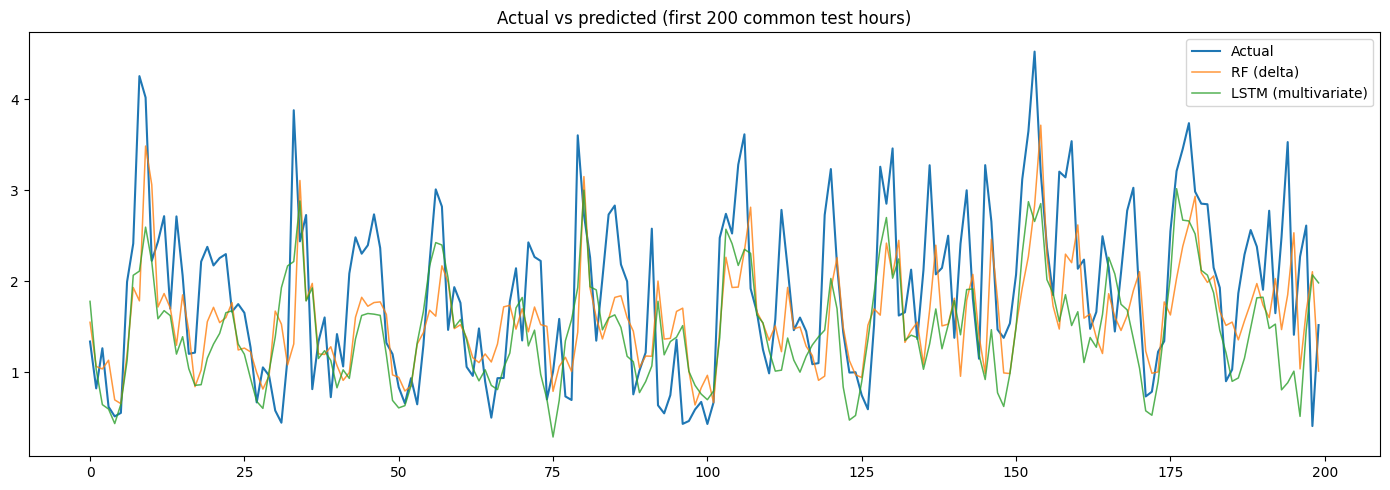

In [7]:
plt.figure(figsize=(14, 5))
plt.plot(y_common.values[:200], label="Actual", linewidth=1.5)
plt.plot(all_preds["Random Forest (delta, 1h)"].values[:200], label="RF (delta)", linewidth=1.1, alpha=0.8)
plt.plot(all_preds["LSTM (multivariate)"].values[:200], label="LSTM (multivariate)", linewidth=1.1, alpha=0.8)
plt.legend()
plt.title("Actual vs predicted (first 200 common test hours)")
plt.tight_layout()
plt.show()

comparison.to_csv(f"{WORK_DIR}/model_comparison.csv")

In [8]:
best = comparison["MAE (kW)"].idxmin()
rf_mae = comparison.loc["Random Forest (delta, 1h)", "MAE (kW)"]
lstm_best = comparison.loc[["LSTM (univariate)", "LSTM (multivariate)"], "MAE (kW)"].min()
print("Lowest MAE overall      :", best)
print("RF (delta) MAE          :", rf_mae)
print("Best LSTM MAE           :", lstm_best)
print("RF better than best LSTM:", rf_mae < lstm_best)

Lowest MAE overall      : Persistence (t-1h)
RF (delta) MAE          : 0.2892
Best LSTM MAE           : 0.3194
RF better than best LSTM: True


### Key findings

- Read the table above for the exact numbers. In our full study (all houses, same protocol) the **Random Forest with the delta target beat the LSTMs**, and **persistence is a very hard baseline at 1 hour ahead**.
- Tree-based models often beat deep learning on small-to-moderate, feature-rich tabular data, because the engineered lag features already carry most of the useful signal. LSTM results also vary from run to run (random initialisation), so small differences between the two LSTM variants should not be over-interpreted.
- **The Random Forest (delta) is selected as the final forecasting model** for deployment and for the multi-city study. The LSTM stays in the project as a documented comparison (appendix).

**Next notebook:** `04_anomaly_detection.ipynb`